In [2]:
import os
import json
import math
import numpy as np 
import pandas as pd

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
# Torchvision
import torchvision
from torchvision.datasets import FashionMNIST
from torchvision import transforms

## Imports for plotting
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
import matplotlib
# matplotlib.rcParams['lines.linewidth'] = 2.0

%matplotlib inline 
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg', 'pdf') # For export

import seaborn as sns


In [3]:
device = torch.device("cuda:2" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
print("Device:", device)

Device: mps


## Przygotowanie danych

In [4]:
# Transformations applied on each image => only make them a tensor
transform = transforms.Compose([transforms.ToTensor()])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = FashionMNIST(root="data/", train=True, transform=transform, download=True)

# Loading the test set
test_set = FashionMNIST(root="data/", train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_dataset, batch_size=256, shuffle=True, drop_last=True, pin_memory=True, num_workers=4)
test_loader = data.DataLoader(test_set, batch_size=256, shuffle=False, drop_last=False, num_workers=4)

def get_train_images(num):
    return torch.stack([test_set[i][0] for i in range(10,10+num)], dim=0)

100%|██████████| 26.4M/26.4M [00:09<00:00, 2.84MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 220kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.53MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 374kB/s]


# Generative Adversarial Networks

In [6]:
class Discriminator(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(Discriminator, self).__init__()

        self.fc_1 = nn.Linear(input_dim, hidden_dim)
        self.fc_2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc_out  = nn.Linear(hidden_dim, 1)
        
        self.LeakyReLU = nn.LeakyReLU(0.2)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = self.LeakyReLU(self.fc_1(x))
        x = self.LeakyReLU(self.fc_2(x))
        x = self.fc_out(x)
        return x

In [7]:
class Generator(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super(Generator, self).__init__()
        self.fc_1 = nn.Linear(latent_dim, hidden_dim)
        self.fc_2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc_3 = nn.Linear(hidden_dim, output_dim)
        
        self.LeakyReLU = nn.LeakyReLU(0.2)
        
    def forward(self, x):
        h     = self.LeakyReLU(self.fc_1(x))
        h     = self.LeakyReLU(self.fc_2(h))
        
        x_hat = torch.sigmoid(self.fc_3(h))
        x_hat = x_hat.view([-1, 1, 28, 28])
        return x_hat

In [8]:
# Models
latent_dim = 32
generator = Generator(latent_dim=latent_dim, hidden_dim=256, output_dim=784).to(device)
discriminator = Discriminator( hidden_dim=256, input_dim=784).to(device)

# Optimizers
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0001)
generator_scheduler = optim.lr_scheduler.ExponentialLR(optimizer=generator_optimizer, gamma=0.99)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=0.0001)
discriminator_scheduler = optim.lr_scheduler.ExponentialLR(optimizer=discriminator_optimizer, gamma=0.99)

# loss
criterion = nn.MSELoss()

In [9]:
fixed_noise = torch.randn(16, latent_dim,device=device)

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 0, discrimiantor fake error: 0.0716, discriminator real acc: 0.814


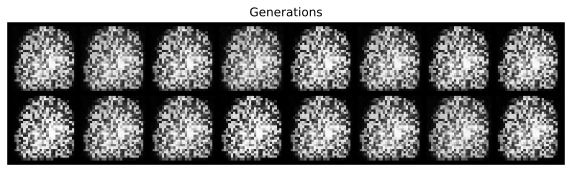

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 1, discrimiantor fake error: 0.0367, discriminator real acc: 0.936
Epoch: 2, discrimiantor fake error: 0.0243, discriminator real acc: 0.957
Epoch: 3, discrimiantor fake error: 0.00737, discriminator real acc: 0.976
Epoch: 4, discrimiantor fake error: 0.00271, discriminator real acc: 0.99
Epoch: 5, discrimiantor fake error: 0.00172, discriminator real acc: 0.995
Epoch: 6, discrimiantor fake error: 0.00215, discriminator real acc: 0.996
Epoch: 7, discrimiantor fake error: 0.00375, discriminator real acc: 0.996
Epoch: 8, discrimiantor fake error: 0.0157, discriminator real acc: 0.988
Epoch: 9, discrimiantor fake error: 0.0257, discriminator real acc: 0.978
Epoch: 10, discrimiantor fake error: 0.0255, discriminator real acc: 0.97


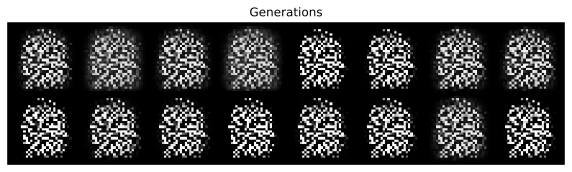

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 11, discrimiantor fake error: 0.0124, discriminator real acc: 0.98
Epoch: 12, discrimiantor fake error: 0.00616, discriminator real acc: 0.99
Epoch: 13, discrimiantor fake error: 0.00518, discriminator real acc: 0.993
Epoch: 14, discrimiantor fake error: 0.00916, discriminator real acc: 0.991
Epoch: 15, discrimiantor fake error: 0.0326, discriminator real acc: 0.977
Epoch: 16, discrimiantor fake error: 0.0702, discriminator real acc: 0.945
Epoch: 17, discrimiantor fake error: 0.0316, discriminator real acc: 0.959
Epoch: 18, discrimiantor fake error: 0.019, discriminator real acc: 0.976
Epoch: 19, discrimiantor fake error: 0.0233, discriminator real acc: 0.978
Epoch: 20, discrimiantor fake error: 0.0333, discriminator real acc: 0.969


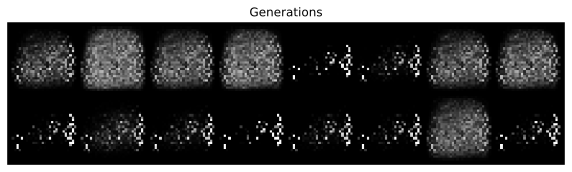

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 21, discrimiantor fake error: 0.0226, discriminator real acc: 0.974
Epoch: 22, discrimiantor fake error: 0.0162, discriminator real acc: 0.981
Epoch: 23, discrimiantor fake error: 0.0229, discriminator real acc: 0.977
Epoch: 24, discrimiantor fake error: 0.0394, discriminator real acc: 0.965
Epoch: 25, discrimiantor fake error: 0.0326, discriminator real acc: 0.966
Epoch: 26, discrimiantor fake error: 0.0257, discriminator real acc: 0.974
Epoch: 27, discrimiantor fake error: 0.0219, discriminator real acc: 0.976
Epoch: 28, discrimiantor fake error: 0.0265, discriminator real acc: 0.972
Epoch: 29, discrimiantor fake error: 0.0296, discriminator real acc: 0.97
Epoch: 30, discrimiantor fake error: 0.0361, discriminator real acc: 0.967


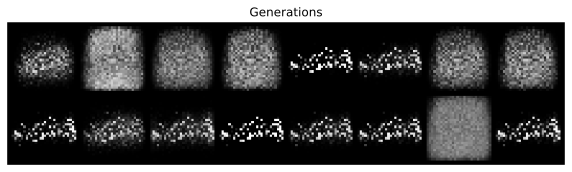

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 31, discrimiantor fake error: 0.0352, discriminator real acc: 0.962
Epoch: 32, discrimiantor fake error: 0.0288, discriminator real acc: 0.97
Epoch: 33, discrimiantor fake error: 0.0319, discriminator real acc: 0.968
Epoch: 34, discrimiantor fake error: 0.0372, discriminator real acc: 0.964
Epoch: 35, discrimiantor fake error: 0.0455, discriminator real acc: 0.957
Epoch: 36, discrimiantor fake error: 0.0407, discriminator real acc: 0.956
Epoch: 37, discrimiantor fake error: 0.042, discriminator real acc: 0.959
Epoch: 38, discrimiantor fake error: 0.0452, discriminator real acc: 0.958
Epoch: 39, discrimiantor fake error: 0.0456, discriminator real acc: 0.953
Epoch: 40, discrimiantor fake error: 0.0401, discriminator real acc: 0.96


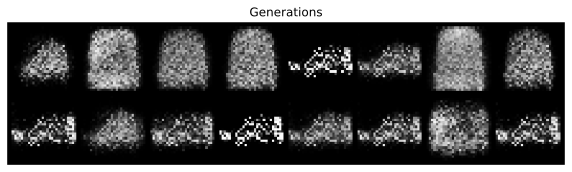

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 41, discrimiantor fake error: 0.0387, discriminator real acc: 0.962
Epoch: 42, discrimiantor fake error: 0.0401, discriminator real acc: 0.96
Epoch: 43, discrimiantor fake error: 0.0455, discriminator real acc: 0.957
Epoch: 44, discrimiantor fake error: 0.0465, discriminator real acc: 0.954
Epoch: 45, discrimiantor fake error: 0.0419, discriminator real acc: 0.958
Epoch: 46, discrimiantor fake error: 0.0462, discriminator real acc: 0.957
Epoch: 47, discrimiantor fake error: 0.0473, discriminator real acc: 0.954
Epoch: 48, discrimiantor fake error: 0.05, discriminator real acc: 0.95
Epoch: 49, discrimiantor fake error: 0.0473, discriminator real acc: 0.955
Epoch: 50, discrimiantor fake error: 0.0538, discriminator real acc: 0.948


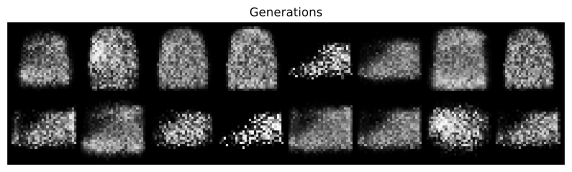

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 51, discrimiantor fake error: 0.0529, discriminator real acc: 0.949
Epoch: 52, discrimiantor fake error: 0.0503, discriminator real acc: 0.953
Epoch: 53, discrimiantor fake error: 0.0561, discriminator real acc: 0.948
Epoch: 54, discrimiantor fake error: 0.0593, discriminator real acc: 0.944
Epoch: 55, discrimiantor fake error: 0.0616, discriminator real acc: 0.938
Epoch: 56, discrimiantor fake error: 0.0612, discriminator real acc: 0.943
Epoch: 57, discrimiantor fake error: 0.0603, discriminator real acc: 0.945
Epoch: 58, discrimiantor fake error: 0.0625, discriminator real acc: 0.937
Epoch: 59, discrimiantor fake error: 0.0625, discriminator real acc: 0.941
Epoch: 60, discrimiantor fake error: 0.0576, discriminator real acc: 0.947


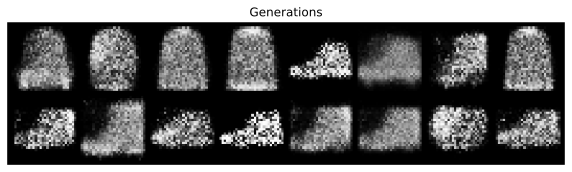

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 61, discrimiantor fake error: 0.0646, discriminator real acc: 0.939
Epoch: 62, discrimiantor fake error: 0.0666, discriminator real acc: 0.936
Epoch: 63, discrimiantor fake error: 0.065, discriminator real acc: 0.934
Epoch: 64, discrimiantor fake error: 0.0706, discriminator real acc: 0.935
Epoch: 65, discrimiantor fake error: 0.0663, discriminator real acc: 0.932
Epoch: 66, discrimiantor fake error: 0.0717, discriminator real acc: 0.93
Epoch: 67, discrimiantor fake error: 0.0703, discriminator real acc: 0.933
Epoch: 68, discrimiantor fake error: 0.0741, discriminator real acc: 0.93
Epoch: 69, discrimiantor fake error: 0.0692, discriminator real acc: 0.933
Epoch: 70, discrimiantor fake error: 0.0727, discriminator real acc: 0.933


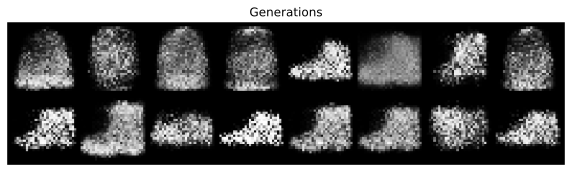

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 71, discrimiantor fake error: 0.0831, discriminator real acc: 0.922
Epoch: 72, discrimiantor fake error: 0.0809, discriminator real acc: 0.918
Epoch: 73, discrimiantor fake error: 0.0824, discriminator real acc: 0.923
Epoch: 74, discrimiantor fake error: 0.0838, discriminator real acc: 0.92
Epoch: 75, discrimiantor fake error: 0.0847, discriminator real acc: 0.915
Epoch: 76, discrimiantor fake error: 0.0797, discriminator real acc: 0.92
Epoch: 77, discrimiantor fake error: 0.0843, discriminator real acc: 0.918
Epoch: 78, discrimiantor fake error: 0.0796, discriminator real acc: 0.922
Epoch: 79, discrimiantor fake error: 0.0815, discriminator real acc: 0.921
Epoch: 80, discrimiantor fake error: 0.0844, discriminator real acc: 0.916


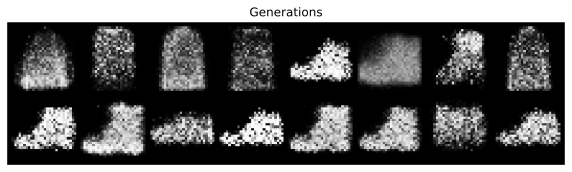

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 81, discrimiantor fake error: 0.0818, discriminator real acc: 0.914
Epoch: 82, discrimiantor fake error: 0.0938, discriminator real acc: 0.91
Epoch: 83, discrimiantor fake error: 0.0848, discriminator real acc: 0.917
Epoch: 84, discrimiantor fake error: 0.0945, discriminator real acc: 0.902
Epoch: 85, discrimiantor fake error: 0.097, discriminator real acc: 0.904
Epoch: 86, discrimiantor fake error: 0.096, discriminator real acc: 0.904
Epoch: 87, discrimiantor fake error: 0.101, discriminator real acc: 0.893
Epoch: 88, discrimiantor fake error: 0.107, discriminator real acc: 0.892
Epoch: 89, discrimiantor fake error: 0.104, discriminator real acc: 0.896
Epoch: 90, discrimiantor fake error: 0.0992, discriminator real acc: 0.899


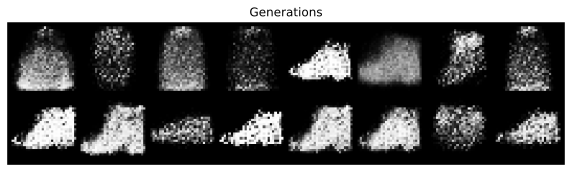

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch: 91, discrimiantor fake error: 0.0952, discriminator real acc: 0.902
Epoch: 92, discrimiantor fake error: 0.0966, discriminator real acc: 0.901
Epoch: 93, discrimiantor fake error: 0.0995, discriminator real acc: 0.899
Epoch: 94, discrimiantor fake error: 0.0956, discriminator real acc: 0.901
Epoch: 95, discrimiantor fake error: 0.0998, discriminator real acc: 0.899
Epoch: 96, discrimiantor fake error: 0.101, discriminator real acc: 0.898
Epoch: 97, discrimiantor fake error: 0.0963, discriminator real acc: 0.9
Epoch: 98, discrimiantor fake error: 0.101, discriminator real acc: 0.898
Epoch: 99, discrimiantor fake error: 0.118, discriminator real acc: 0.886


In [10]:
G_losses = []
D_losses = []
num_epochs = 100
for epoch in range(num_epochs):
    # For each batch in the dataloader
    discriminator_fake_acc = []
    discriminator_real_acc = []
    for i, data in enumerate(train_loader, 0):

        ############################
        # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
        ###########################
        ## Train with all-real batch
        discriminator_optimizer.zero_grad()
        # Format batch
        real_images = data[0].to(device)
        b_size = real_images.size(0)
        label = torch.ones((b_size,), dtype=torch.float, device=device) # Setting labels for real images
        # Forward pass real batch through D
        output = discriminator(real_images).view(-1)
        # Calculate loss on all-real batch
        error_discriminator_real = criterion(output, label)
        # Calculate gradients for D in backward pass
        discriminator_real_acc.append(output.mean().item())

        ## Train with all-fake batch
        # Generate batch of latent vectors
        noise = torch.randn(b_size, latent_dim,device=device)
        # Generate fake image batch with Generator
        fake_images = generator(noise)
        label_fake = torch.zeros((b_size,), dtype=torch.float, device=device)
        # Classify all fake batch with Discriminator
        output = discriminator(fake_images.detach()).view(-1)
        # Calculate D's loss on the all-fake batch
        error_discriminator_fake = criterion(output, label_fake)
        # Calculate the gradients for this batch, accumulated (summed) with previous gradients
        discriminator_fake_acc.append(output.mean().item())
        # Compute error of D as sum over the fake and the real batches
        error_discriminator = error_discriminator_real + error_discriminator_fake
        error_discriminator.backward()
        # Update D
        discriminator_optimizer.step()

        ############################
        # (2) Update G network: maximize log(D(G(z)))
        ###########################
        generator_optimizer.zero_grad()
        label = torch.ones((b_size,), dtype=torch.float, device=device)  # fake labels are real for generator cost
        # Since we just updated D, perform another forward pass of all-fake batch through D
        output = discriminator(fake_images).view(-1)
        # Calculate G's loss based on this output
        error_generator = criterion(output, label)
        # Calculate gradients for G
        error_generator.backward()
        D_G_z2 = output.mean().item()
        # Update G
        generator_optimizer.step()

        # Output training stats
        # Save Losses for plotting later
        G_losses.append(error_generator.item())
        D_losses.append(error_discriminator.item())

    print(f"Epoch: {epoch}, discrimiantor fake error: {np.mean(discriminator_fake_acc):.3}, discriminator real acc: {np.mean(discriminator_real_acc):.3}")
    generator_scheduler.step()
    discriminator_scheduler.step()
    if epoch % 10 == 0:
        with torch.no_grad():
            fake = generator(fixed_noise).detach().cpu()
        grid = torchvision.utils.make_grid(fake)
        grid = grid.permute(1, 2, 0)
        plt.figure(figsize=(10,10))
        plt.title(f"Generations")
        plt.imshow(grid)
        plt.axis('off')
        plt.show()

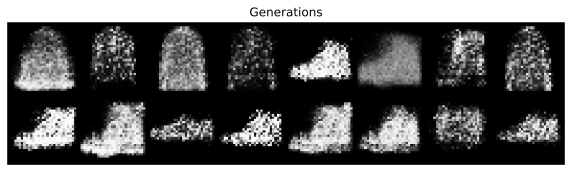

In [11]:
with torch.no_grad():
    fake = generator(fixed_noise).detach().cpu()
grid = torchvision.utils.make_grid(fake)
grid = grid.permute(1, 2, 0)
plt.figure(figsize=(10,10))
plt.title(f"Generations")
plt.imshow(grid)
plt.axis('off')
plt.show()

## Mini Zadanie: stwórzmy model warunkowany klasą
Może się przydać F.one_hot

In [12]:
from torch.nn.functional import one_hot

In [13]:
one_hot(torch.tensor([4,3,4]),10)

tensor([[0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]])

# Modele dyfuzyjne

#### Zaszumianie danych

In [16]:
def corrupt(x, amount):
    """Corrupt the input `x` by mixing it with noise according to `amount`"""
    noise = torch.rand_like(x)
    amount = amount.view(-1, 1, 1, 1) # Sort shape so broadcasting works
    return x*(1-amount) + noise*amount

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Input shape: torch.Size([8, 1, 28, 28])


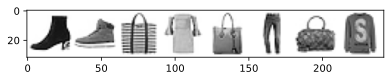

In [14]:
x, y = next(iter(train_loader))
x = x[:8]
print('Input shape:', x.shape)
plt.imshow(torchvision.utils.make_grid(x)[0], cmap='Greys');

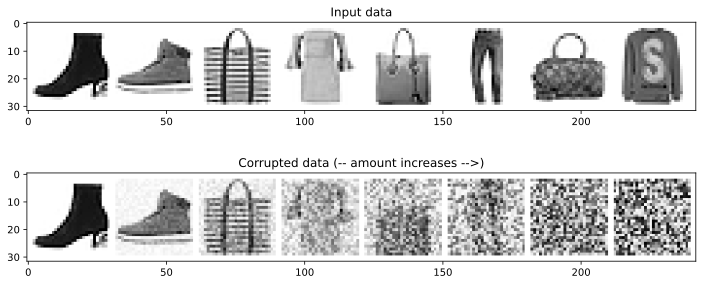

In [17]:
# Plotting the input data
fig, axs = plt.subplots(2, 1, figsize=(12, 5))
axs[0].set_title('Input data')
axs[0].imshow(torchvision.utils.make_grid(x)[0], cmap='Greys')

# Adding noise
amount = torch.linspace(0, 1, x.shape[0]) # Left to right -> more corruption
noised_x = corrupt(x, amount)

# Plotting the noised version
axs[1].set_title('Corrupted data (-- amount increases -->)')
axs[1].imshow(torchvision.utils.make_grid(noised_x)[0], cmap='Greys');

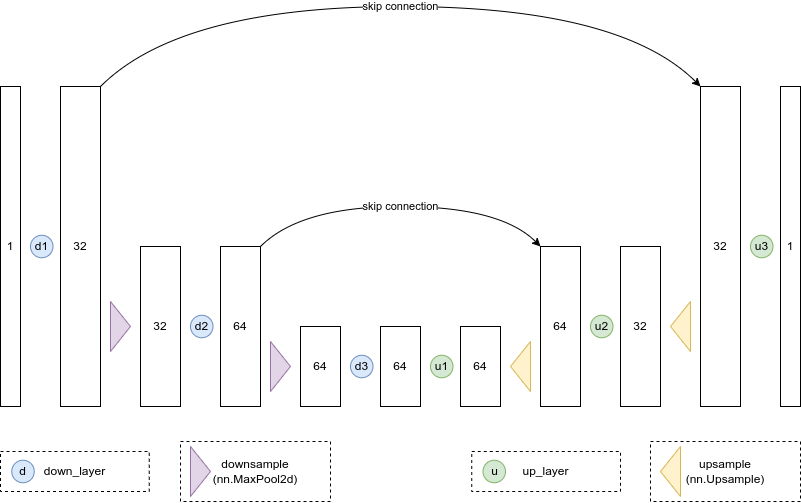

In [18]:
class BasicUNet(nn.Module):
    """A minimal UNet implementation."""
    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()
        self.down_layers = torch.nn.ModuleList([
            nn.Conv2d(in_channels, 32, kernel_size=5, padding=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.Conv2d(64, 64, kernel_size=5, padding=2),
        ])
        self.up_layers = torch.nn.ModuleList([
            nn.Conv2d(64 + 1, 64, kernel_size=5, padding=2), #Dodajmy warunkowanie "krokiem odszumiania"
            nn.Conv2d(64, 32, kernel_size=5, padding=2),
            nn.Conv2d(32, out_channels, kernel_size=5, padding=2),
        ])
        self.act = nn.SiLU() # The activation function
        self.downscale = nn.MaxPool2d(2)
        self.upscale = nn.Upsample(scale_factor=2)

    def forward(self, x, t):
        h = []
        for i, layer in enumerate(self.down_layers):
            x = self.act(layer(x))
            if i < 2: # Dla wszystki warstw "down" poza ostatnim
              h.append(x) # Zapisujemy "skip-connetions"
              x = self.downscale(x) # Zmniejszamy wymiarowość, i propagujemy do kolejnej warstwy
        t = t.repeat(1,x.size(2),x.size(3),1).permute(3,0,1,2)
        x = torch.cat([x,t],dim=1)
        for i, layer in enumerate(self.up_layers):
            if i > 0: # Dla wszystkich warstw up poza pierwszą
              x = self.upscale(x) # Upscale
              x += h.pop() # Dodajemy zapisane skip-connection
            x = self.act(layer(x))

        return x

In [19]:
net = BasicUNet().to(device)
net

BasicUNet(
  (down_layers): ModuleList(
    (0): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  )
  (up_layers): ModuleList(
    (0): Conv2d(65, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Conv2d(64, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (2): Conv2d(32, 1, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  )
  (act): SiLU()
  (downscale): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (upscale): Upsample(scale_factor=2.0, mode='nearest')
)

In [20]:
sum([p.numel() for p in net.parameters()]) #Malutki model, najnowsze modele mają po kilka miliardów parametrów

310657

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Finished epoch 0. Average loss for this epoch: 0.035885
Finished epoch 1. Average loss for this epoch: 0.026742
Finished epoch 2. Average loss for this epoch: 0.024159
Finished epoch 3. Average loss for this epoch: 0.022251
Finished epoch 4. Average loss for this epoch: 0.021338
Finished epoch 5. Average loss for this epoch: 0.020271
Finished epoch 6. Average loss for this epoch: 0.019924
Finished epoch 7. Average loss for this epoch: 0.019534
Finished epoch 8. Average loss for this epoch: 0.019253
Finished epoch 9. Average loss for this epoch: 0.018918
Finished epoch 10. Average loss for this epoch: 0.018727
Finished epoch 11. Average loss for this epoch: 0.018684
Finished epoch 12. Average loss for this epoch: 0.018442
Finished epoch 13. Average loss for this epoch: 0.018371
Finished epoch 14. Average loss for this epoch: 0.018181
Finished epoch 15. Average loss for this epoch: 0.017893
Finished epoch 16. Average loss for this epoch: 0.017638
Finished epoch 17. Average loss for this 

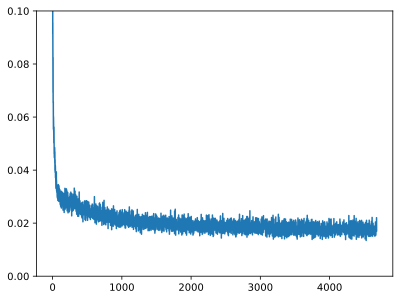

In [21]:
n_epochs = 20

# Create the network
net = BasicUNet()
net.to(device)

# Funkcja straty - zwykłe MSE
loss_fn = nn.MSELoss()

# Optymalizator
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

# Wartości funkcji straty
losses = []

# The training loop
for epoch in range(n_epochs):

    for x, y in train_loader:

        # Przygotowanie danych
        x = x.to(device)
        # Losowanie ilości dodanego szumu - może być krok, albo jak w tym przypadku ciągła wartość w %
        noise_amount = torch.rand(x.shape[0]).to(device) 
        noisy_x = corrupt(x, noise_amount) # Zaszumiony przykład

        # Predykcja oryginalnego - czystego obrazka
        pred = net(noisy_x, noise_amount)

        # Porównanie z oryginalnym obrazkiem
        loss = loss_fn(pred, x) # 
 
        opt.zero_grad()
        loss.backward()
        opt.step()

        losses.append(loss.item())

    # Średni loss per epoka:
    avg_loss = sum(losses[-len(train_loader):])/len(train_loader)
    print(f'Finished epoch {epoch}. Average loss for this epoch: {avg_loss:05f}')

# View the loss curve
plt.plot(losses)
plt.ylim(0, 0.1)

## Jak dobrze model potrafi odszumiać dane?

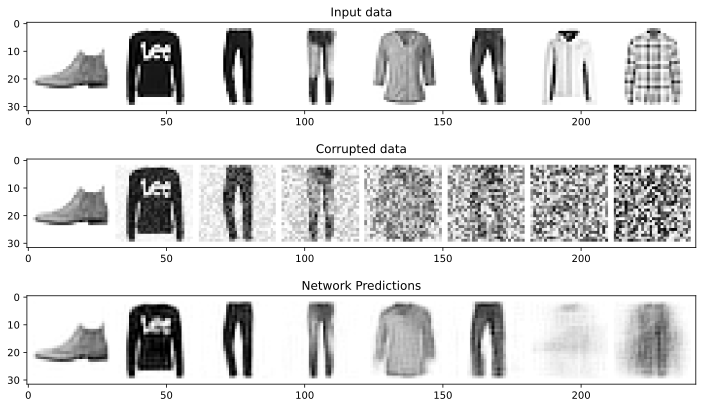

In [22]:
# Fetch some data
x, y = next(iter(test_loader))
x = x[:8] # Only using the first 8 for easy plotting

# Corrupt with a range of amounts
amount = torch.linspace(0, 1, x.shape[0]) # Left to right -> more corruption
noised_x = corrupt(x, amount)

# Get the model predictions
with torch.no_grad():
  preds = net(noised_x.to(device), amount.to(device)).detach().cpu()

# Plot
fig, axs = plt.subplots(3, 1, figsize=(12, 7))
axs[0].set_title('Input data')
axs[0].imshow(torchvision.utils.make_grid(x)[0].clip(0, 1), cmap='Greys')
axs[1].set_title('Corrupted data')
axs[1].imshow(torchvision.utils.make_grid(noised_x)[0].clip(0, 1), cmap='Greys')
axs[2].set_title('Network Predictions')
axs[2].imshow(torchvision.utils.make_grid(preds)[0].clip(0, 1), cmap='Greys');

#### Dokończ metodę samplowania
W każdym kroku t , przewidujemy oryginalny obrazek x, który chcemy zaszumić z powrotem do kroku t-1

Timestep: 1.0
Timestep: 0.8
Timestep: 0.6
Timestep: 0.4
Timestep: 0.2


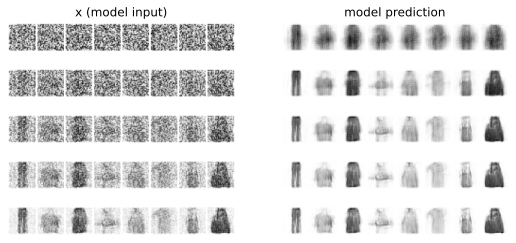

In [23]:
#Sampling strategy: Break the process into 5 steps and move 1/5'th of the way there each time:
n_steps = 5
x = torch.rand(8, 1, 28, 28).to(device) # Start from random
step_history = [x.detach().cpu()]
pred_output_history = []

for i in range(n_steps):
    t = (torch.zeros(x.size(0)) + (n_steps - i)/n_steps).to(device)
    print(f"Timestep: {t[0].item():.2}")
    with torch.no_grad():
        pred = net(x, t) # Predict the denoised x0
    pred_output_history.append(pred.detach().cpu()) # Store model output for plotting
    #---------- Uzupełnij proces generowania
    mix_factor = 1/(n_steps - i)
    x = x*(1-mix_factor) + pred*mix_factor
    #---------------------------------------
    step_history.append(x.detach().cpu()) # Store step for plotting

fig, axs = plt.subplots(n_steps, 2, figsize=(9, 4), sharex=True)
axs[0,0].set_title('x (model input)')
axs[0,1].set_title('model prediction')
for i in range(n_steps):
    axs[i, 0].imshow(torchvision.utils.make_grid(step_history[i])[0].clip(0, 1), cmap='Greys')
    axs[i, 1].imshow(torchvision.utils.make_grid(pred_output_history[i])[0].clip(0, 1), cmap='Greys')
    axs[i, 0].axis('off')
    axs[i, 1].axis('off')

### Generacje przy 40 krokach odszumiania

(np.float64(-0.5), np.float64(241.5), np.float64(241.5), np.float64(-0.5))

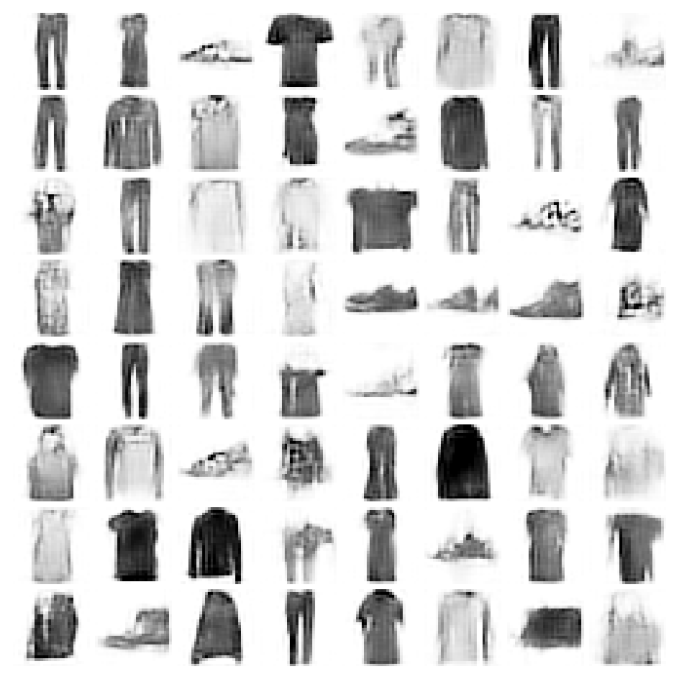

In [24]:
#Showing more results, using 40 sampling steps
n_steps = 40
x = torch.rand(64, 1, 28, 28).to(device)
for i in range(n_steps):
  t = (torch.zeros(x.size(0)) + (n_steps - i)/n_steps).to(device)
  noise_amount = torch.ones((x.shape[0], )).to(device) * (1-(i/n_steps)) # Starting high going low
  with torch.no_grad():
    pred = net(x, t)
#-----------Samplowanie
    mix_factor = 1/(n_steps - i)
    x = x*(1-mix_factor) + pred*mix_factor
#----------------------
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
ax.imshow(torchvision.utils.make_grid(x.detach().cpu(), nrow=8)[0].clip(0, 1), cmap='Greys')
ax.axis('off')

# Ewaluacja modeli generatywnych

### Stwórzmy prosty klasyfikator

In [25]:
class Evaluator(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(Evaluator, self).__init__()

        self.fc_1 = nn.Linear(input_dim, hidden_dim)
        self.fc_2 = nn.Linear(hidden_dim, 50)
        self.fc_out  = nn.Linear(50, 10)
        
        self.LeakyReLU = nn.LeakyReLU(0.2)
        
    def get_features(self, x):
        x = torch.flatten(x, 1)
        x = self.LeakyReLU(self.fc_1(x))
        x = self.LeakyReLU(self.fc_2(x))
        return x
    

    def forward(self, x):
        x = self.get_features(x)
        x = self.fc_out(x)
        return x

evaluator = Evaluator(28*28, 256).to(device)

In [26]:
# Optimizers
optimizer = torch.optim.Adam(evaluator.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ExponentialLR(optimizer=optimizer, gamma=0.97)

# loss
criterion = nn.CrossEntropyLoss()

In [27]:
num_epochs = 7
for epoch in range(num_epochs):
    for data, targets in iter(train_loader):
        data = data.to(device)
        targets = targets.to(device)

        results = evaluator(data)
        loss = criterion(results, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


In [28]:
num_correct = 0
total_guesses = 0

evaluator.eval()
with torch.no_grad():
    for data, targets in iter(test_loader):
        # Sends data and targets to device
        data = data.to(device)
        targets = targets.to(device)

        # Acquires the network's best guesses at each class
        results = evaluator(data)
        best_guesses = torch.argmax(results, 1)

        # Updates number of correct and total guesses
        num_correct += torch.eq(targets, best_guesses).sum().item()
        total_guesses += len(targets)

print("Correctly guessed ", num_correct/total_guesses*100, "% of the dataset")

Correctly guessed  86.52 % of the dataset


In [29]:
with torch.no_grad():
    fixed_noise = torch.randn(1000, latent_dim,device=device)
    generations_gan = generator(fixed_noise)
    # generations_vae = vae.decoder(fixed_noise)

In [30]:
n_steps = 40
x = torch.rand(1000, 1, 28, 28).to(device)
with torch.no_grad():
    for i in range(n_steps):
      t = (torch.zeros(x.size(0)) + (n_steps - i)/n_steps).to(device)
      noise_amount = torch.ones((x.shape[0], )).to(device) * (1-(i/n_steps)) # Starting high going low
      with torch.no_grad():
        pred = net(x, t)
    #-----------Samplowanie
        # x = pred
        mix_factor = 1/(n_steps - i)
        x = x*(1-mix_factor) + pred*mix_factor
generations_diffusion = x

In [31]:
orig_data = [x[0] for x in list(test_set)[:1000]]
orig_data = torch.cat(orig_data)

In [32]:
with torch.no_grad():
    dist_orig_data = evaluator.get_features(orig_data.to(device)).cpu()
    dist_gan = evaluator.get_features(generations_gan.to(device)).cpu()
    dist_diff = evaluator.get_features(generations_diffusion.to(device)).cpu()
    # dist_vae = evaluator.get_features(generations_vae.to(device)).cpu()

In [33]:
dist_diff.shape

torch.Size([1000, 50])

### Możemy ręcznie przeglądać poszczególne wymiary i oglądać nieścisłości względem rzeczywistych danych

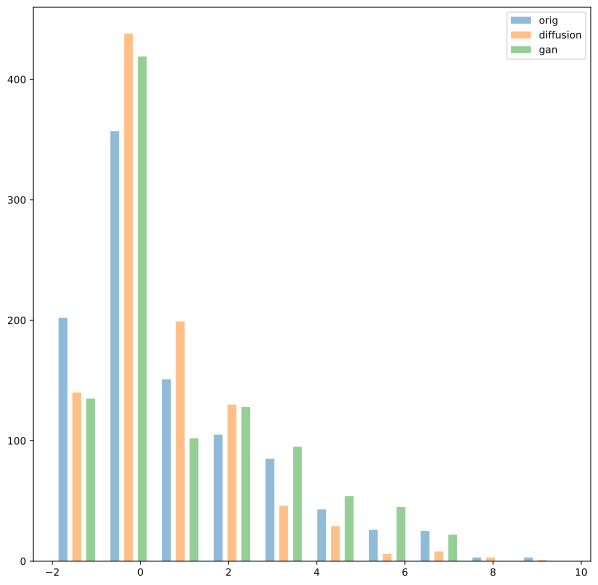

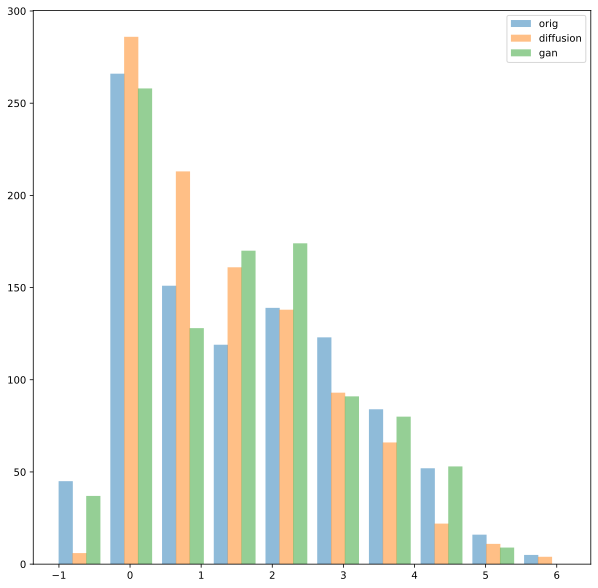

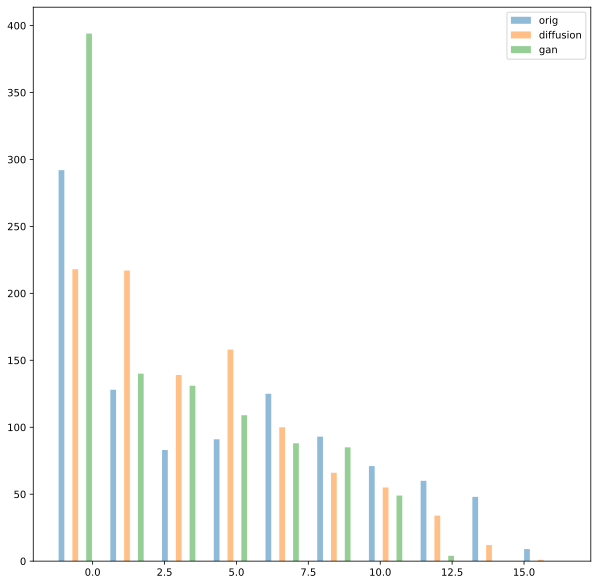

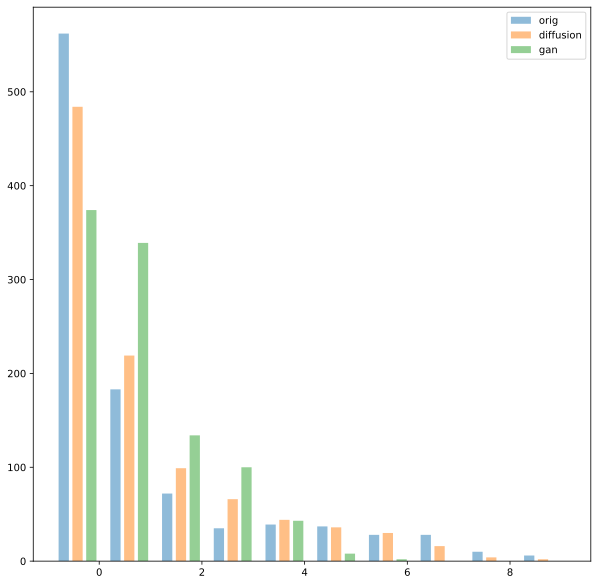

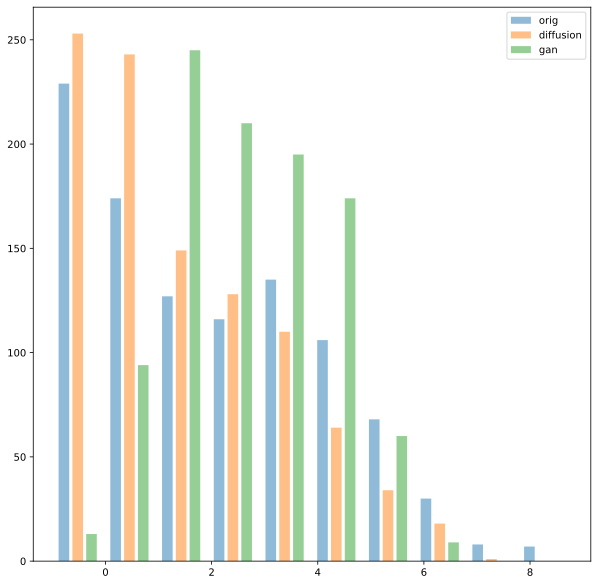

In [ ]:
# przechodzimy przez 5 pierwszych z 50 neuronów (wyciągniętych z ostatniej warstwy po aktywacji) 
# i patrzymy na ich aktywacje (czyli wagi) i sprawdzamy jakie wartości, blisko jakich wartości całkowitych są te wagi
for idx in range(5):
    bins = 10
    w = 0.2
    plt.figure(figsize=(10,10))
    plt.hist([dist_orig_data[:,idx].numpy(),dist_diff[:,idx].numpy(),dist_gan[:,idx]], bins, alpha=0.5, label=['orig','diffusion','gan'],width=w)
    plt.legend(loc='upper right')
    plt.show()
    plt.close()

## Albo wykorzystać gotową metrykę (FID):

In [35]:
######### Frechet Inception distance based on implementation from https://github.com/mseitzer/pytorch-fid

import numpy as np
from scipy import linalg


def calculate_frechet_distance(distribution_1, distribution_2, eps=1e-6):
    mu1 = np.mean(distribution_1, axis=0)
    sigma1 = np.cov(distribution_1, rowvar=False)

    mu2 = np.mean(distribution_2, axis=0)
    sigma2 = np.cov(distribution_2, rowvar=False)

    """Numpy implementation of the Frechet Distance.
    The Frechet distance between two multivariate Gaussians X_1 ~ N(mu_1, C_1)
    and X_2 ~ N(mu_2, C_2) is
            d^2 = ||mu_1 - mu_2||^2 + Tr(C_1 + C_2 - 2*sqrt(C_1*C_2)).
    Stable version by Dougal J. Sutherland.
    Params:
    -- mu1   : Numpy array containing the activations of a layer of the
               inception net (like returned by the function 'get_predictions')
               for generated samples.
    -- mu2   : The sample mean over activations, precalculated on an
               representative data set.
    -- sigma1: The covariance matrix over activations for generated samples.
    -- sigma2: The covariance matrix over activations, precalculated on an
               representative data set.
    Returns:
    --   : The Frechet Distance.
    """

    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)

    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)

    assert mu1.shape == mu2.shape, \
        'Training and test mean vectors have different lengths'
    assert sigma1.shape == sigma2.shape, \
        'Training and test covariances have different dimensions'

    diff = mu1 - mu2

    # Product might be almost singular
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if not np.isfinite(covmean).all():
        msg = ('fid calculation produces singular product; '
               'adding %s to diagonal of cov estimates') % eps
        print(msg)
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))

    # Numerical error might give slight imaginary component
    if np.iscomplexobj(covmean):
        if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
            m = np.max(np.abs(covmean.imag))
            raise ValueError('Imaginary component {}'.format(m))
        covmean = covmean.real

    tr_covmean = np.trace(covmean)

    return (diff.dot(diff) + np.trace(sigma1) +
            np.trace(sigma2) - 2 * tr_covmean)

In [36]:
orig_data_2 = [x[0] for x in list(test_set)[-1000:]]
orig_data_2 = torch.cat(orig_data_2)
with torch.no_grad():
    dist_orig_data_2 = evaluator.get_features(orig_data_2.to(device)).cpu()

In [37]:
for name, obj in zip(['orig','diff','gan','cond_gan'],[dist_orig_data_2.numpy(),dist_diff.numpy(),dist_gan.numpy()]):
    print(f"FD {name}: {calculate_frechet_distance(dist_orig_data.numpy(),obj)}")

FD orig: 1.8883430958863983
FD diff: 32.77480937031214
FD gan: 138.63876098104856


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_28692/2261845342.py:46: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


### Im mniej tym lepiej, z zastrzeżeniem że nawet 2 części oryginalnego datasetu będą się trochę między sobą różniły (nigdy FID nie będzie równe 0)